In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Printf, Statistics
gr(); default(left_margin = 6Plots.mm, bottom_margin = 6Plots.mm)

## Data

In [ ]:
datadir = joinpath(@__DIR__, "HW2_data")
readmat(f) = Matrix{Float64}(CSV.read(joinpath(datadir, f), DataFrame)[:, 2:end])

c = readmat("energy.csv")                                         
r = readmat("utilization.csv")                                     
C = CSV.read(joinpath(datadir, "capacity.csv"), DataFrame).capacity 
U = CSV.read(joinpath(datadir, "maxutil.csv"),  DataFrame).maxutil  

n, m = size(c)
@assert size(r) == (n, m) && length(C) == m && length(U) == m
(n = n, m = m, total_capacity = sum(C), total_maxutil = sum(U))

(n = 1000, m = 20, total_capacity = 1000.0, total_maxutil = 30045.508167750442)

In [ ]:
function solve_allocation(w, K)
    model = Model(Gurobi.Optimizer)
    set_silent(model)

    @variable(model, x[1:n, 1:m] >= 0)
    @constraint(model, assign[i = 1:n], sum(x[i, j] for j in 1:m) == 1)
    @constraint(model, machine[j = 1:m], sum(w[i, j] * x[i, j] for i in 1:n) <= K[j])
    @objective(model, Min, sum(c[i, j] * x[i, j] for i in 1:n, j in 1:m))

    optimize!(model)
    @assert termination_status(model) == MOI.OPTIMAL
    return (obj = objective_value(model), X = value.(x), q = dual.(machine), p = dual.(assign))
end

tol = 1e-6
best = [argmin(c[i, :]) for i in 1:n];  

In [4]:
E_free = sum(minimum(c[i, :]) for i in 1:n)
@printf("Energy with no machine constraints: %.2f\n", E_free)

Energy with no machine constraints: 40883.16


## (b)

In [5]:
cap = solve_allocation(ones(n, m), C)

not_best_b   = count(i -> cap.X[i, best[i]] < 1 - tol, 1:n)
split_b      = count(i -> maximum(cap.X[i, :]) < 1 - tol, 1:n)
jobs_per_mach = vec(sum(cap.X, dims = 1))

@printf("1. Optimal energy consumption              : %.2f\n", cap.obj)
@printf("2. Energy ignoring capacities              : %.2f\n", E_free)
@printf("   Cost of capacity limits                 : %.2f (%.2f%%)\n", cap.obj - E_free, 100 * (cap.obj - E_free) / E_free)
@printf("3. Jobs not fully on lowest-energy machine : %d of %d\n", not_best_b, n)
println()
println("Jobs split across machines: $split_b")
println("All machines at full capacity: $(all(jobs_per_mach .>= C .- tol))")

Set parameter Username
Set parameter LicenseID to value 2857457
Academic license - for non-commercial use only - expires 2027-08-26
1. Optimal energy consumption              : 41416.51
2. Energy ignoring capacities              : 40883.16


   Cost of capacity limits                 : 533.35 (1.30%)
3. Jobs not fully on lowest-energy machine : 386 of 1000



Jobs split across machines: 0
All machines at full capacity: true


In [6]:
DataFrame(machine = 1:m, capacity = C, jobs_assigned = round.(jobs_per_mach, digits = 3),
          jobs_preferring = [count(==(j), best) for j in 1:m])

Row,machine,capacity,jobs_assigned,jobs_preferring
,Int64,Float64,Float64,Int64
1,1,23.0,23.0,54
2,2,24.0,24.0,58
3,3,30.0,30.0,42
4,4,4.0,4.0,48
5,5,70.0,70.0,47
6,6,87.0,87.0,43
7,7,75.0,75.0,43
8,8,107.0,107.0,49
9,9,43.0,43.0,50


The optimal energy consumption is $41{,}416.51$. If machine capacities
were ignored, the minimum energy consumption would be $40{,}883.16$.
Thus, the capacity constraints increase total energy consumption by
$533.35$, or about $1.3\%$.

In the optimal solution, $386$ of the $1000$ jobs are not assigned to
their lowest-energy machine. This happens because some of the machines
that are best for many jobs do not have enough capacity to process all
of them, so some jobs must be assigned to their second- or third-best
machines.

Also, since
$
\sum_{j=1}^{20} C_j=1000,
$
which is exactly the total number of jobs, every machine must be used at
full capacity. The solution is integral, so no job is split across
multiple machines, which is consistent with the network-flow
integrality result from part (a).

## (e)

In [7]:
util = solve_allocation(r, U)

not_best_e = count(i -> util.X[i, best[i]] < 1 - tol, 1:n)
split_e    = count(i -> maximum(util.X[i, :]) < 1 - tol, 1:n)
used_util  = [sum(r[i, j] * util.X[i, j] for i in 1:n) for j in 1:m]

@printf("1. Optimal energy consumption              : %.2f\n", util.obj)
@printf("2. Energy ignoring utilization             : %.2f\n", E_free)
@printf("   Cost of utilization limits              : %.2f (%.2f%%)\n", util.obj - E_free, 100 * (util.obj - E_free) / E_free)
@printf("3. Jobs not fully on lowest-energy machine : %d of %d\n", not_best_e, n)
println()
println("Jobs split across machines: $split_e")
println("Machines at full utilization: $(count(used_util .>= U .- tol)) of $m")

Set parameter Username
Set parameter LicenseID to value 2857457
Academic license - for non-commercial use only - expires 2027-08-26
1. Optimal energy consumption              : 46693.58
2. Energy ignoring utilization             : 40883.16


   Cost of utilization limits              : 5810.42 (14.21%)
3. Jobs not fully on lowest-energy machine : 885 of 1000

Jobs split across machines: 20
Machines at full utilization: 20 of 20


The optimal energy consumption is $46{,}693.58$. If the utilization
constraints were ignored, the minimum energy consumption would be
$40{,}883.16$. Thus, the utilization constraints increase total energy
consumption by $5{,}810.42$, or about $14.2\%$.

In the optimal solution, $885$ of the $1000$ jobs are not fully assigned
to their lowest-energy machine. This is because the utilization
constraints are more restrictive than the simple capacity constraints
in part (b). We have different jobs use different amounts of utilization on
different machines.

Unlike part (b), the optimal solution is not integral. In this solution,
$20$ jobs are split across multiple machines. All $20$ machines also
operate at their maximum utilization.

## (f)

In [8]:
q = util.q    # JuMP convention: q[j] ≤ 0 for a ≤ constraint in a minimization, matching part (c)
DataFrame(machine = 1:m, maxutil = round.(U, digits = 1), dual = round.(q, digits = 4),
          util_used = round.(used_util ./ U, digits = 4))

Row,machine,maxutil,dual,util_used
,Int64,Float64,Float64,Float64
1,1,1170.7,-0.6877,1.0
2,2,1356.7,-0.6276,1.0
3,3,774.6,-0.7476,1.0
4,4,583.4,-0.9423,1.0
5,5,806.4,-0.7983,1.0
6,6,327.1,-0.9559,1.0
7,7,3895.1,-0.4764,1.0
8,8,591.4,-0.8631,1.0
9,9,1968.6,-0.5627,1.0


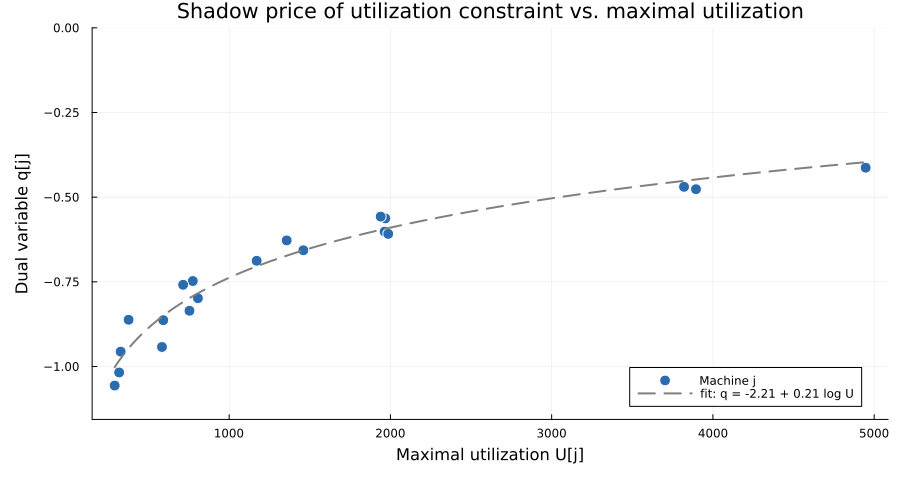

In [ ]:
a, b = [ones(m) log.(U)] \ q
Ugrid = range(minimum(U), maximum(U), length = 200)

scatter(U, q; color = "#2b6cb0", markersize = 6, markerstrokecolor = :white, label = "Machine j",
        xlabel = "Maximal utilization U[j]", ylabel = "Dual variable q[j]",
        title = "Shadow price of utilization constraint vs. maximal utilization",
        ylims = (minimum(q) - 0.1, 0), legend = :bottomright, size = (900, 480))
plot!(Ugrid, a .+ b .* log.(Ugrid); color = :gray, linestyle = :dash, linewidth = 2,
      label = @sprintf("fit: q = %.2f + %.2f log U", a, b))

In [10]:
@printf("Range of duals: [%.3f, %.3f]\n", minimum(q), maximum(q))
@printf("Correlation(U, q)      = %.3f\n", cor(U, q))
@printf("Correlation(log U, q)  = %.3f\n", cor(log.(U), q))

Range of duals: [-1.056, -0.413]
Correlation(U, q)      = 0.878
Correlation(log U, q)  = 0.976


**Comments.**

All of the dual variables are negative, ranging from approximately
$-1.06$ to $-0.41$. Since each $q_j<0$, complementary slackness implies
that all of the machine utilization constraints are binding.

The magnitude of $q_j$ represents the value of additional utilization
capacity. For example, a dual value of $-1.06$ means that increasing
the maximal utilization of that machine by one unit would reduce the
optimal energy consumption by approximately $1.06$ units.

From the scatter plot, machines with smaller maximal utilization tend
to have more negative dual values, while machines with larger maximal
utilization tend to have dual values closer to zero. Thus, additional
utilization appears to be more valuable for machines with tighter
utilization limits.